# Práctica 1. Construcción de un corpus textual

## 1. Descripción del corpus

| | |
|---|---|
| **Fuente** | EMSCAD (*Employment Scam Aegean Dataset*), recolectado por la Universidad del Egeo. Ofertas de empleo publicadas entre 2012 y 2014 y anotadas manualmente como legítimas o fraudulentas. Distribuido en Kaggle como *Real / Fake Job Posting Prediction*. Archivo `DataSet.csv` |
| **Tema** | Reclutamiento y empleo en línea |
| **Idioma** | Inglés |
| **Documentos** | 17,880 ofertas (una oferta = un documento) |
| **Palabras** | 7,320,172 en los cinco campos de texto libre |
| **Etiqueta** | `fraudulent` (`t`/`f`) |

Justificación de la selección: el corpus supera con holgura las 80,000 palabras recomendadas,
procede de una fuente identificable con anotación manual, y su texto conserva el marcado HTML
original, lo que permite trabajar la limpieza sobre ruido real. La etiqueta `fraudulent` habilita
comparaciones entre subcorpus durante el resto del semestre, y el mismo material sirve para las
prácticas posteriores de modelos estadísticos, análisis morfosintáctico, sintáctico y
representación semántica.

In [1]:
import gzip, html, json, re, unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize, word_tokenize

for recurso, ruta in [("punkt", "tokenizers/punkt"), ("punkt_tab", "tokenizers/punkt_tab"),
                      ("stopwords", "corpora/stopwords")]:
    try:
        nltk.data.find(ruta)
    except LookupError:
        nltk.download(recurso, quiet=True)

IDIOMA = "english"
CSV_PATH = Path("DataSet.csv")
if not CSV_PATH.exists():
    CSV_PATH = Path.home() / "Downloads" / "DataSet.csv"

AZUL, NARANJA, VERDE, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS, REJILLA = "#52514e", "#dcdcd8"
plt.rcParams.update({
    "figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.frameon": False,
    "legend.fontsize": 8.5, "axes.edgecolor": REJILLA, "axes.labelcolor": GRIS,
    "xtick.color": GRIS, "ytick.color": GRIS,
})

def estilizar(ax, rejilla="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color=REJILLA, linewidth=0.8)
        ax.set_axisbelow(True)

In [2]:
crudo = pd.read_csv(CSV_PATH)
CAMPOS_TEXTO = ["title", "company_profile", "description", "requirements", "benefits"]

inventario = pd.DataFrame({
    "palabras": [int(crudo[c].fillna("").astype(str).str.split().str.len().sum())
                 for c in CAMPOS_TEXTO],
    "cobertura_%": [round(100 * crudo[c].notna().mean(), 1) for c in CAMPOS_TEXTO],
}, index=CAMPOS_TEXTO)

print(f"Registros: {len(crudo):,} x {crudo.shape[1]} columnas")
print(f"Palabras en los campos de texto libre: {inventario['palabras'].sum():,}\n")
inventario

Registros: 17,880 x 18 columnas
Palabras en los campos de texto libre: 7,320,172



,palabras,cobertura_%
title,67263,100.0
company_profile,1715608,81.5
description,3325153,100.0
requirements,1604117,85.0
benefits,608031,59.8


## 2. Carga y limpieza del texto

Cada documento es la concatenación de los cinco campos de texto libre, separados por salto de
línea. Los campos vacíos se tratan como cadena vacía en lugar de descartar el registro, porque
`benefits` y `company_profile` faltan en muchas ofertas y eliminarlas reduciría el corpus sin
motivo.

Decisiones de limpieza:

- **Entidades HTML.** Se decodifican en dos pasadas, porque parte del corpus trae secuencias
  doblemente escapadas (`&amp;amp;`) que una sola pasada dejaría a medio resolver.
- **Etiquetas de bloque** (`</p>`, `</li>`, `<br>`). Se sustituyen por salto de línea y no por
  cadena vacía, para no pegar palabras de viñetas contiguas (`cookingWe`).
- **Resto del marcado** (`<b>`, `<a href=...>`). Se elimina, ya que es formato sin valor semántico.
- **Marcadores de anonimización** (`#URL_...#`, `#EMAIL_...#`, `#PHONE_...#`). Los autores del
  dataset sustituyeron con ellos enlaces y contactos. Se eliminan porque el hash no aporta
  contenido léxico y generaría tokens únicos que inflan el vocabulario.
- **Caracteres especiales.** Normalización Unicode NFKC, que además convierte el espacio duro
  `U+00A0`. Las comillas y guiones tipográficos se pasan a su equivalente ASCII, de modo que
  el apóstrofo curvo de `don’t` (U+2019) y el recto de `don't` (U+0027) acaben siendo el mismo
  token.
- **Espacios y formato.** Se compactan los espacios repetidos y las líneas en blanco. El salto de
  línea sí se conserva, porque muchas ofertas son listas de viñetas sin puntuación final y esa es
  la única frontera disponible para segmentar en oraciones.
- **Documentos repetidos.** El corpus contiene anuncios publicados varias veces, incluido un texto
  fraudulento que aparece 21 veces. Se eliminan usando como firma los primeros 400 caracteres
  normalizados. Sin este paso, las frecuencias léxicas reflejarían el número de republicaciones de
  una campaña y no el uso real del vocabulario.

In [3]:
RE_ETIQUETA = re.compile(r"</?[a-zA-Z][^>]*>")
RE_BLOQUE = re.compile(r"</?(p|div|li|ul|ol|br|h[1-6]|tr|td|table|section)[^>]*>", re.I)
RE_ANONIMO = re.compile(r"#(?:URL|EMAIL|PHONE)_[0-9a-fA-F]+#")
RE_ENTIDAD = re.compile(r"&[a-zA-Z]+;|&#\d+;")
RE_ESPACIOS = re.compile(r"[^\S\n]+")     # espacios horizontales, sin tocar los saltos
RE_LINEAS = re.compile(r"\n\s*\n+")
TIPOGRAFICOS = str.maketrans({
    "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-",
    "\u2014": "-", "\u2026": "...", "\u00a0": " ", "\u200b": "",
})

def limpiar(texto):
    t = html.unescape(html.unescape(texto))
    t = RE_BLOQUE.sub("\n", t)
    t = RE_ETIQUETA.sub(" ", t)
    t = RE_ANONIMO.sub(" ", t)
    t = unicodedata.normalize("NFKC", t).translate(TIPOGRAFICOS)
    t = t.replace("\r\n", "\n").replace("\r", "\n")
    t = RE_LINEAS.sub("\n", RE_ESPACIOS.sub(" ", t))
    return "\n".join(linea.strip() for linea in t.split("\n")).strip()

corpus = crudo[["title", "industry", "function"]].copy()
corpus["categoria"] = np.where(crudo["fraudulent"] == "t", "Fraudulenta", "Legítima")
corpus["texto_crudo"] = crudo[CAMPOS_TEXTO].apply(
    lambda f: "\n".join(str(v).strip() for v in f if pd.notna(v)), axis=1)

texto_total = "\n".join(corpus["texto_crudo"])
print("Ruido detectado antes de limpiar:")
for nombre, n in [("Etiquetas HTML", len(RE_ETIQUETA.findall(texto_total))),
                  ("Entidades HTML", len(RE_ENTIDAD.findall(texto_total))),
                  ("Marcadores de anonimización", len(RE_ANONIMO.findall(texto_total))),
                  ("Saltos CRLF", texto_total.count("\r\n")),
                  ("Espacios duros U+00A0", texto_total.count("\xa0"))]:
    print(f"  {nombre:<30} {n:>9,}")

corpus["texto_limpio"] = corpus["texto_crudo"].apply(limpiar)
corpus = corpus[corpus["texto_limpio"].str.len() > 0]
print(f"\nReducción de caracteres: "
      f"{1 - corpus['texto_limpio'].str.len().sum() / corpus['texto_crudo'].str.len().sum():.1%}")

firma = (corpus["texto_limpio"].str.lower()
         .str.replace(r"[^a-z0-9]", "", regex=True).str[:400])
antes = len(corpus)
corpus = corpus[~firma.duplicated()].reset_index(drop=True)
corpus.insert(0, "doc_id", [f"doc_{i:05d}" for i in range(len(corpus))])
print(f"Documentos repetidos eliminados: {antes - len(corpus):,}")
print(f"Documentos en el corpus final: {len(corpus):,}")

Ruido detectado antes de limpiar:


  Etiquetas HTML                 1,140,817
  Entidades HTML                    22,249
  Marcadores de anonimización       26,363
  Saltos CRLF                      460,117
  Espacios duros U+00A0            307,393



Reducción de caracteres: 17.3%


Documentos repetidos eliminados: 3,615
Documentos en el corpus final: 14,265


In [4]:
ejemplo = corpus.loc[1]
print("ANTES:\n", repr(ejemplo["texto_crudo"][:330]))
print("\nDESPUÉS:\n", repr(ejemplo["texto_limpio"][:330]))

ANTES:
 'Customer Service - Cloud Video Production\n<h3>90 Seconds, the worlds Cloud Video Production Service.</h3>\r\n<p>90 Seconds is the worlds Cloud Video Production Service enabling brands and agencies to get high quality online video content shot and produced anywhere in the world. 90 Seconds makes video production fast, affordable, a'

DESPUÉS:
 'Customer Service - Cloud Video Production\n90 Seconds, the worlds Cloud Video Production Service.\n90 Seconds is the worlds Cloud Video Production Service enabling brands and agencies to get high quality online video content shot and produced anywhere in the world. 90 Seconds makes video production fast, affordable, and all manage'


## 3. Tokenización y segmentación

La segmentación en oraciones se hace en dos niveles. Aplicar `Punkt` sobre el documento completo
daría malos resultados, porque las viñetas no llevan punto final y quedarían fundidas en una sola
oración muy larga. Por eso se parte primero por saltos de línea, que son las fronteras de bloque
recuperadas del HTML, y dentro de cada bloque se aplica `sent_tokenize`, que maneja correctamente
abreviaturas como `Inc.` o `Ph.D.`.

Para la tokenización se usa `word_tokenize` (estándar Treebank), que separa la puntuación como
token independiente y divide las contracciones (`don't` en `do` + `n't`). En esta fase no se altera
el texto: se conservan mayúsculas y signos, porque la normalización es una decisión posterior.

In [5]:
def segmentar(texto):
    return [oracion for bloque in texto.split("\n") if bloque.strip()
            for oracion in sent_tokenize(bloque.strip(), language=IDIOMA)]

corpus["oraciones"] = corpus["texto_limpio"].apply(segmentar)
corpus["tokens_crudos"] = corpus["texto_limpio"].apply(
    lambda t: word_tokenize(t, language=IDIOMA))
corpus["n_oraciones"] = corpus["oraciones"].str.len()

fragmento = corpus.loc[1, "texto_limpio"][:300]
print("TEXTO:", fragmento)
print("\nORACIONES:")
for i, o in enumerate(segmentar(fragmento)[:4], 1):
    print(f"  {i}. {o}")
print("\nTOKENS:", word_tokenize(fragmento, language=IDIOMA)[:26])
print(f"\nTotal: {corpus['n_oraciones'].sum():,} oraciones y "
      f"{corpus['tokens_crudos'].str.len().sum():,} tokens")

TEXTO: Customer Service - Cloud Video Production
90 Seconds, the worlds Cloud Video Production Service.
90 Seconds is the worlds Cloud Video Production Service enabling brands and agencies to get high quality online video content shot and produced anywhere in the world. 90 Seconds makes video production fa

ORACIONES:
  1. Customer Service - Cloud Video Production
  2. 90 Seconds, the worlds Cloud Video Production Service.
  3. 90 Seconds is the worlds Cloud Video Production Service enabling brands and agencies to get high quality online video content shot and produced anywhere in the world.
  4. 90 Seconds makes video production fa

TOKENS: ['Customer', 'Service', '-', 'Cloud', 'Video', 'Production', '90', 'Seconds', ',', 'the', 'worlds', 'Cloud', 'Video', 'Production', 'Service', '.', '90', 'Seconds', 'is', 'the', 'worlds', 'Cloud', 'Video', 'Production', 'Service', 'enabling']

Total: 471,700 oraciones y 6,576,763 tokens


## 4. Normalización

- **Minúsculas.** `Manager`, `manager` y `MANAGER` son el mismo tipo léxico. Sin este paso el
  vocabulario se infla y las listas de frecuencia se fragmentan, sobre todo porque los títulos de
  las ofertas abusan de las mayúsculas (`URGENT HIRING`).
- **Puntuación.** Se descartan los tokens que son sólo signos, ya que encabezarían cualquier
  ranking de frecuencia sin aportar información, y se recorta la puntuación de los extremos
  (`(remote)` pasa a `remote`). Los guiones y apóstrofos internos se conservan, porque
  `full-time`, `e-commerce` o `client's` son unidades léxicas del dominio.
- **Cifras sueltas.** Se descartan los tokens sin ninguna letra; su información ya está en los
  metadatos.
- **Stopwords.** Se generan dos capas: los tokens normalizados completos, necesarios para la ley
  de Zipf y para los modelos de n-gramas de la siguiente práctica, y una capa de contenido sin
  stopwords para el análisis temático. Eliminarlas de forma irreversible impediría el trabajo
  posterior.
- **Stemming y lematización.** No se aplican en esta práctica. Son transformaciones destructivas y
  el análisis morfológico corresponde a una práctica posterior, así que se conserva la forma
  flexionada.
- **Acentos.** Se conservan, ya homogeneizados por NFKC, porque nombres propios como `Zürich`
  pierden identidad si se les quita el diacrítico.

In [6]:
STOPWORDS = set(stopwords.words(IDIOMA))
RE_LETRA = re.compile(r"[a-zA-Z]")
PUNTUACION = "\"'`.,;:!?()[]{}<>*_/\\|-–—…&#@$%+=~^"

def normalizar(tokens):
    return [t for t in (tok.lower().strip(PUNTUACION) for tok in tokens)
            if t and RE_LETRA.search(t)]

corpus["tokens"] = corpus["tokens_crudos"].apply(normalizar)
corpus["tokens_contenido"] = corpus["tokens"].apply(
    lambda ts: [t for t in ts if t not in STOPWORDS and len(t) > 2])
corpus["n_tokens"] = corpus["tokens"].str.len()
corpus["long_oracion_media"] = np.where(
    corpus["n_oraciones"] > 0, corpus["n_tokens"] / corpus["n_oraciones"], 0)

ej = corpus.loc[1, "tokens_crudos"][:26]
print("TOKENS CRUDOS:", ej)
print("\nNORMALIZADOS :", normalizar(ej))
print("\nSIN STOPWORDS:", [t for t in normalizar(ej)
                           if t not in STOPWORDS and len(t) > 2])
print(f"\nDescartado al normalizar: "
      f"{1 - corpus['n_tokens'].sum() / corpus['tokens_crudos'].str.len().sum():.1%}")

TOKENS CRUDOS: ['Customer', 'Service', '-', 'Cloud', 'Video', 'Production', '90', 'Seconds', ',', 'the', 'worlds', 'Cloud', 'Video', 'Production', 'Service', '.', '90', 'Seconds', 'is', 'the', 'worlds', 'Cloud', 'Video', 'Production', 'Service', 'enabling']

NORMALIZADOS : ['customer', 'service', 'cloud', 'video', 'production', 'seconds', 'the', 'worlds', 'cloud', 'video', 'production', 'service', 'seconds', 'is', 'the', 'worlds', 'cloud', 'video', 'production', 'service', 'enabling']

SIN STOPWORDS: ['customer', 'service', 'cloud', 'video', 'production', 'seconds', 'worlds', 'cloud', 'video', 'production', 'service', 'seconds', 'worlds', 'cloud', 'video', 'production', 'service', 'enabling']

Descartado al normalizar: 12.8%


## 5. Estadísticas iniciales del corpus

In [7]:
todos_tokens = [t for ts in corpus["tokens"] for t in ts]
tokens_contenido = [t for ts in corpus["tokens_contenido"] for t in ts]
frecuencias = Counter(todos_tokens)
frec_contenido = Counter(tokens_contenido)
n_tokens, vocabulario = len(todos_tokens), len(frecuencias)
hapax = sum(1 for f in frecuencias.values() if f == 1)
long_oraciones = np.array([len(word_tokenize(o, language=IDIOMA))
                           for ors in corpus["oraciones"] for o in ors])

resumen = pd.DataFrame([
    ("Documentos", f"{len(corpus):,}"),
    ("Palabras (tokens normalizados)", f"{n_tokens:,}"),
    ("Tokens crudos (con puntuación)", f"{corpus['tokens_crudos'].str.len().sum():,}"),
    ("Tokens sin stopwords", f"{len(tokens_contenido):,}"),
    ("Oraciones", f"{corpus['n_oraciones'].sum():,}"),
    ("Vocabulario (tipos)", f"{vocabulario:,}"),
    ("Razón tipo/token", f"{vocabulario / n_tokens:.5f}"),
    ("Hapax legomena", f"{hapax:,} ({hapax / vocabulario:.1%} del vocabulario)"),
    ("Longitud media de documento", f"{corpus['n_tokens'].mean():.0f} palabras"),
    ("Longitud mediana de documento", f"{corpus['n_tokens'].median():.0f} palabras"),
    ("Oraciones por documento", f"{corpus['n_oraciones'].mean():.1f}"),
    ("Longitud media de oración", f"{long_oraciones.mean():.1f} palabras"),
    ("Longitud mediana de oración", f"{np.median(long_oraciones):.0f} palabras"),
], columns=["métrica", "valor"])
print(resumen.to_string(index=False))

                       métrica                          valor
                    Documentos                         14,265
Palabras (tokens normalizados)                      5,734,803
Tokens crudos (con puntuación)                      6,576,763
          Tokens sin stopwords                      3,577,655
                     Oraciones                        471,700
           Vocabulario (tipos)                         55,546
              Razón tipo/token                        0.00969
                Hapax legomena 22,035 (39.7% del vocabulario)
   Longitud media de documento                   402 palabras
 Longitud mediana de documento                   376 palabras
       Oraciones por documento                           33.1
     Longitud media de oración                  13.9 palabras
   Longitud mediana de oración                    12 palabras


In [8]:
top_todas = pd.DataFrame(frecuencias.most_common(15), columns=["palabra", "frec"])
top_cont = pd.DataFrame(frec_contenido.most_common(15), columns=["palabra", "frec"])
print(f"Las 20 palabras más frecuentes cubren "
      f"{sum(f for _, f in frecuencias.most_common(20)) / n_tokens:.1%} de las ocurrencias\n")
pd.concat([top_todas.add_prefix("todas_"), top_cont.add_prefix("contenido_")],
          axis=1).set_index(pd.RangeIndex(1, 16))

Las 20 palabras más frecuentes cubren 29.1% de las ocurrencias



,todas_palabra,todas_frec,contenido_palabra,contenido_frec
1,and,303119,experience,39625
2,the,176653,work,32457
3,to,172158,team,30002
4,of,129014,skills,20195
5,a,125560,company,19199
6,in,105745,business,18211
7,with,78736,new,15813
8,for,70080,development,15608
9,we,67848,working,14552
10,you,55276,management,14483


La lista completa está dominada por palabras funcionales (`and`, `the`, `to`), que concentran el
29 % de las ocurrencias, tal como cabe esperar en prosa inglesa. La lista sin stopwords muestra el
dominio: `experience`, `work`, `team`, `skills`, `company`, `business`. Entre las palabras
frecuentes no aparece ningún residuo de marcado (`p`, `li`, `nbsp`), lo que confirma que la
limpieza funcionó.

## 6. Visualización e interpretación

### 6.1 Distribución de longitudes

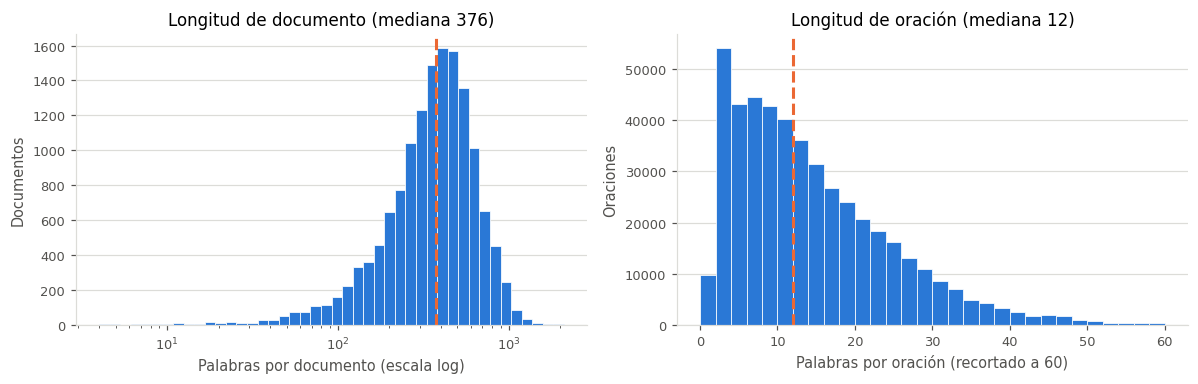

Documento: Q25=251, Q75=517, máximo=2,100


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

bins = np.logspace(np.log10(max(corpus["n_tokens"].min(), 1)),
                   np.log10(corpus["n_tokens"].max()), 45)
ax1.hist(corpus["n_tokens"], bins=bins, color=AZUL, edgecolor="white", linewidth=0.5)
ax1.set_xscale("log")
ax1.axvline(corpus["n_tokens"].median(), color=NARANJA, linewidth=2, linestyle="--")
ax1.set_xlabel("Palabras por documento (escala log)")
ax1.set_ylabel("Documentos")
ax1.set_title(f"Longitud de documento (mediana {corpus['n_tokens'].median():.0f})")
estilizar(ax1)

ax2.hist(long_oraciones[long_oraciones <= 60], bins=np.arange(0, 61, 2),
         color=AZUL, edgecolor="white", linewidth=0.5)
ax2.axvline(np.median(long_oraciones), color=NARANJA, linewidth=2, linestyle="--")
ax2.set_xlabel("Palabras por oración (recortado a 60)")
ax2.set_ylabel("Oraciones")
ax2.set_title(f"Longitud de oración (mediana {np.median(long_oraciones):.0f})")
estilizar(ax2)
fig.tight_layout()
plt.show()

print(f"Documento: Q25={corpus['n_tokens'].quantile(.25):.0f}, "
      f"Q75={corpus['n_tokens'].quantile(.75):.0f}, "
      f"máximo={corpus['n_tokens'].max():,}")

En escala logarítmica la longitud de documento se aproxima a una normal, es decir que la
distribución es aproximadamente log-normal, con el 50 % central entre 251 y 517 palabras. La
longitud de oración, en cambio, tiene la moda en unidades de 2 a 4 palabras y decae de forma
sostenida. Esto responde al género: las ofertas se redactan como listas de viñetas y encabezados, y
cada viñeta cuenta como una unidad oracional. La media (13.9) y la mediana (12) quedan por debajo
de lo habitual en prosa expositiva inglesa, que ronda las 15 a 20 palabras.

### 6.2 Frecuencia de palabras

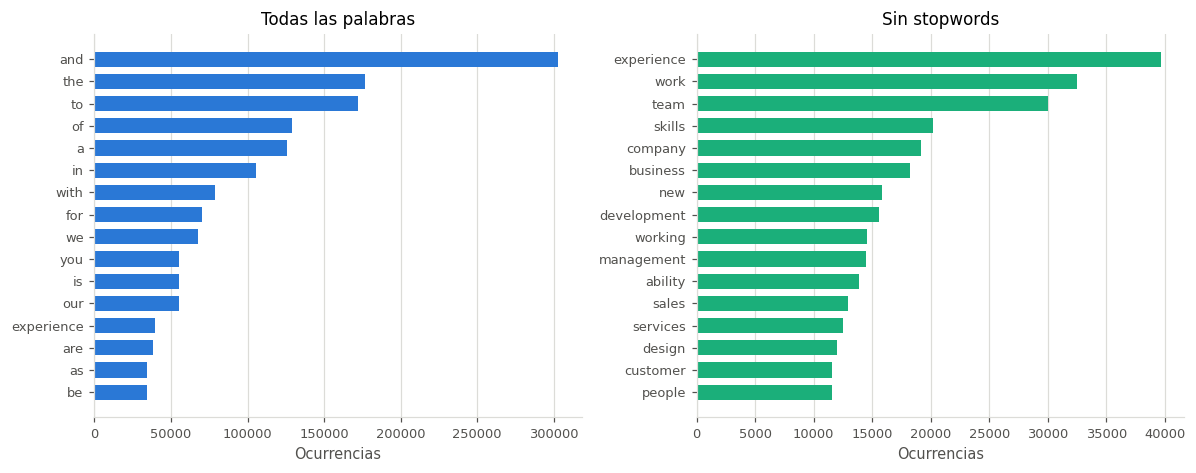

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, datos, color, titulo in [
        (ax1, frecuencias.most_common(16)[::-1], AZUL, "Todas las palabras"),
        (ax2, frec_contenido.most_common(16)[::-1], VERDE, "Sin stopwords")]:
    ax.barh([p for p, _ in datos], [f for _, f in datos], color=color, height=0.68)
    ax.set_title(titulo)
    ax.set_xlabel("Ocurrencias")
    estilizar(ax, rejilla="x")
fig.tight_layout()
plt.show()

El contraste entre los dos paneles justifica haber conservado las dos capas de normalización. La
frecuencia bruta describe la gramática del inglés y sería prácticamente igual en cualquier corpus
del idioma. Al quitar las stopwords aparece el vocabulario propio del dominio: `experience`,
`work`, `team`, `skills`, `development`, `management`. Para el análisis temático conviene filtrar
stopwords; para modelar la lengua, no.

### 6.3 Crecimiento del vocabulario y ley de Zipf

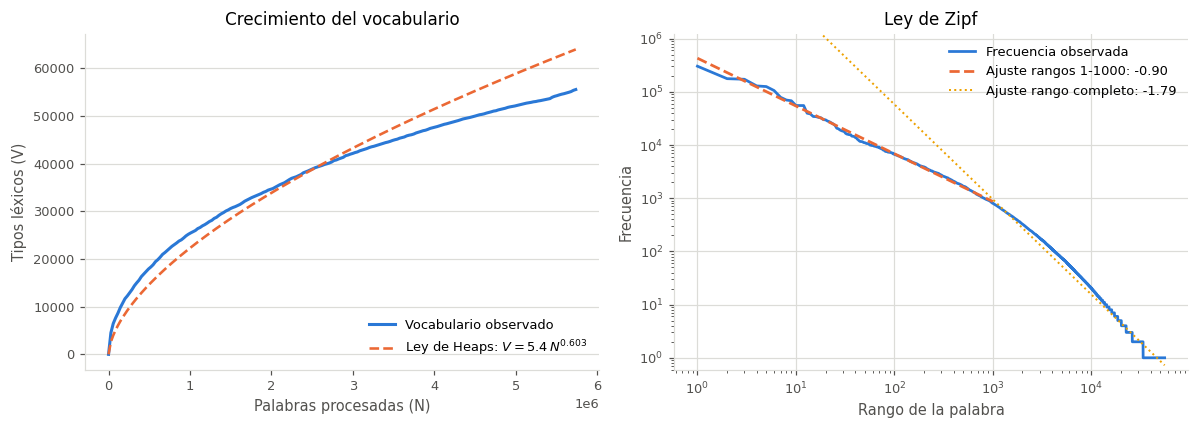

Las   100 palabras más frecuentes cubren 45.2% del corpus
Las 1,000 palabras más frecuentes cubren 76.8% del corpus
Las 5,000 palabras más frecuentes cubren 93.8% del corpus


In [11]:
hitos = set(np.unique(np.linspace(1, n_tokens, 200).astype(int)).tolist())
vistos, x_voc, y_voc = set(), [], []
for i, t in enumerate(todos_tokens, 1):
    vistos.add(t)
    if i in hitos:
        x_voc.append(i)
        y_voc.append(len(vistos))
x_voc, y_voc = np.array(x_voc), np.array(y_voc)
beta, log_k = np.polyfit(np.log(x_voc), np.log(y_voc), 1)
K = np.exp(log_k)

frecs = np.array(sorted(frecuencias.values(), reverse=True))
rangos = np.arange(1, len(frecs) + 1)
CABEZA = 1000
p_cab, i_cab = np.polyfit(np.log10(rangos[:CABEZA]), np.log10(frecs[:CABEZA]), 1)
p_tot, i_tot = np.polyfit(np.log10(rangos), np.log10(frecs), 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(x_voc, y_voc, color=AZUL, linewidth=2, label="Vocabulario observado")
ax1.plot(x_voc, K * x_voc ** beta, color=NARANJA, linewidth=1.7, linestyle="--",
         label=f"Ley de Heaps: $V = {K:.1f}\\,N^{{{beta:.3f}}}$")
ax1.set_xlabel("Palabras procesadas (N)")
ax1.set_ylabel("Tipos léxicos (V)")
ax1.set_title("Crecimiento del vocabulario")
ax1.legend(loc="lower right")
estilizar(ax1)

ax2.loglog(rangos, frecs, color=AZUL, linewidth=1.8, label="Frecuencia observada")
ax2.loglog(rangos[:CABEZA], 10 ** i_cab * rangos[:CABEZA] ** p_cab, color=NARANJA,
           linewidth=1.8, linestyle="--", label=f"Ajuste rangos 1-1000: {p_cab:.2f}")
ax2.loglog(rangos, 10 ** i_tot * rangos ** p_tot, color=AMARILLO, linewidth=1.3,
           linestyle=":", label=f"Ajuste rango completo: {p_tot:.2f}")
ax2.set_ylim(0.6, frecs[0] * 4)
ax2.set_xlabel("Rango de la palabra")
ax2.set_ylabel("Frecuencia")
ax2.set_title("Ley de Zipf")
ax2.legend(loc="upper right")
estilizar(ax2, rejilla="both")
fig.tight_layout()
plt.show()

cobertura = np.cumsum(frecs) / n_tokens
for k in (100, 1000, 5000):
    print(f"Las {k:>5,} palabras más frecuentes cubren {cobertura[k-1]:.1%} del corpus")

La curva de vocabulario es cóncava pero no llega a saturarse: el exponente de Heaps, β ≈ 0.60, cae
en el rango habitual de 0.4 a 0.6 y significa que duplicar el corpus no duplica los tipos léxicos,
aunque sigue aportando palabras nuevas. Cualquier modelo entrenado sobre este corpus encontrará
palabras fuera de vocabulario.

En la gráfica de Zipf conviene distinguir dos tramos. En los primeros 1,000 rangos, que ya cubren
el 77 % del corpus, la pendiente es −0.90, cercana al −1 canónico. Sobre el rango completo baja a
−1.79, pero no porque se incumpla la ley, sino por la caída de la cola, donde se acumula el 40 %
del vocabulario que aparece una sola vez. Como 100 tipos cubren el 45 % de las ocurrencias,
conviene imponer una frecuencia mínima al construir vocabularios o matrices término-documento.

### 6.4 Comparación entre categorías

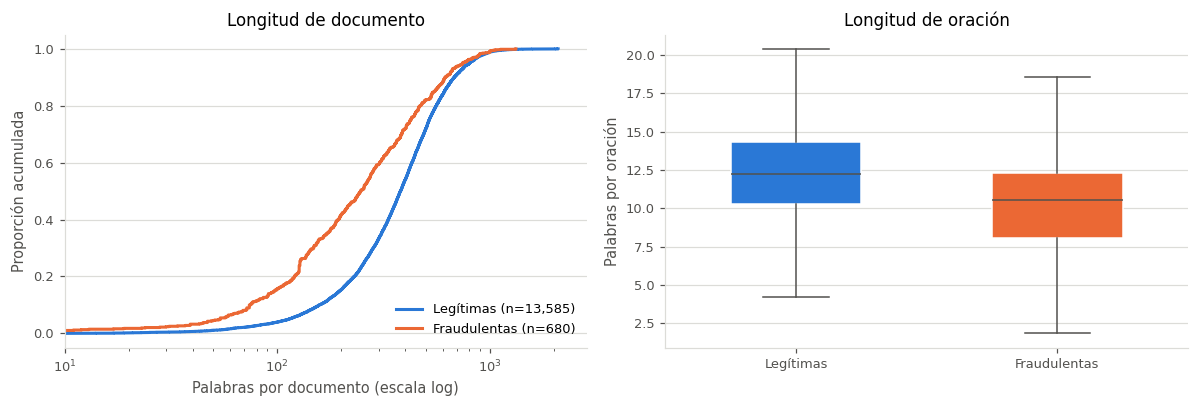

Longitud mediana de documento: legítimas 381, fraudulentas 248 palabras


In [12]:
legitimas = corpus[corpus["categoria"] == "Legítima"]
fraudulentas = corpus[corpus["categoria"] == "Fraudulenta"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

# Distribución acumulada: los grupos tienen tamaños muy dispares y un histograma
# sería ruido de binning.
for datos, color, etiqueta in [
        (legitimas["n_tokens"], AZUL, f"Legítimas (n={len(legitimas):,})"),
        (fraudulentas["n_tokens"], NARANJA, f"Fraudulentas (n={len(fraudulentas):,})")]:
    x = np.sort(datos)
    ax1.step(x, np.arange(1, len(x) + 1) / len(x), where="post",
             color=color, linewidth=2, label=etiqueta)
ax1.set_xscale("log")
ax1.set_xlim(left=10)
ax1.set_xlabel("Palabras por documento (escala log)")
ax1.set_ylabel("Proporción acumulada")
ax1.set_title("Longitud de documento")
ax1.legend(loc="lower right")
estilizar(ax1)

caja = ax2.boxplot([legitimas["long_oracion_media"], fraudulentas["long_oracion_media"]],
                   patch_artist=True, widths=0.5, showfliers=False,
                   tick_labels=["Legítimas", "Fraudulentas"])
for parche, color in zip(caja["boxes"], [AZUL, NARANJA]):
    parche.set_facecolor(color)
    parche.set_edgecolor("white")
for elemento in ("whiskers", "caps", "medians"):
    for linea in caja[elemento]:
        linea.set_color(GRIS)
ax2.set_ylabel("Palabras por oración")
ax2.set_title("Longitud de oración")
estilizar(ax2)
fig.tight_layout()
plt.show()

print(f"Longitud mediana de documento: legítimas {legitimas['n_tokens'].median():.0f}, "
      f"fraudulentas {fraudulentas['n_tokens'].median():.0f} palabras")

La curva acumulada de las ofertas fraudulentas va siempre por delante de la legítima, es decir que
para cualquier umbral de longitud ya se ha acumulado una proporción mayor de ellas: son
sistemáticamente más cortas, con una mediana de 248 palabras frente a 381. La longitud de oración
también baja, pero apenas un par de palabras y las cajas se solapan bastante. La diferencia entre
ambos subcorpus está sobre todo en la extensión del anuncio, no en la complejidad de sus oraciones.

### 6.5 Vocabulario distintivo de cada categoría

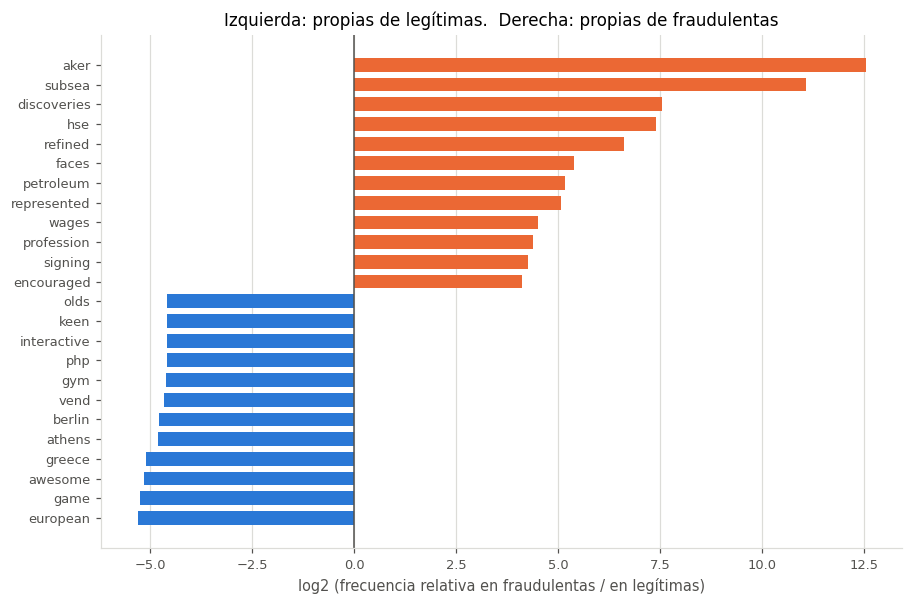

Industria declarada en las ofertas fraudulentas:
industry
Oil & Energy                 107
Accounting                    46
Hospital & Health Care        43
Marketing and Advertising     36


In [13]:
frec_leg = Counter(t for ts in legitimas["tokens_contenido"] for t in ts)
frec_fra = Counter(t for ts in fraudulentas["tokens_contenido"] for t in ts)
docs_leg = Counter(t for ts in legitimas["tokens_contenido"] for t in set(ts))
docs_fra = Counter(t for ts in fraudulentas["tokens_contenido"] for t in set(ts))
total_leg, total_fra = sum(frec_leg.values()), sum(frec_fra.values())

# Se exige un mínimo de ocurrencias y de documentos distintos para que ninguna
# palabra se sostenga sobre unos pocos anuncios.
MIN_FREC, MIN_DOCS = 60, 25
candidatas = {p for p in set(frec_leg) | set(frec_fra)
              if frec_leg[p] + frec_fra[p] >= MIN_FREC}
razones = {}
for p in candidatas:
    r = np.log2(((frec_fra[p] + 1) / (total_fra + len(candidatas))) /
                ((frec_leg[p] + 1) / (total_leg + len(candidatas))))
    if (r > 0 and docs_fra[p] >= MIN_DOCS) or (r < 0 and docs_leg[p] >= MIN_DOCS):
        razones[p] = r

orden = sorted(razones.items(), key=lambda kv: kv[1])
seleccion = orden[:12] + orden[-12:]

fig, ax = plt.subplots(figsize=(8.4, 5.6))
ax.barh(range(len(seleccion)), [v for _, v in seleccion],
        color=[AZUL if v < 0 else NARANJA for _, v in seleccion], height=0.7)
ax.set_yticks(range(len(seleccion)), [p for p, _ in seleccion])
ax.axvline(0, color=GRIS, linewidth=1)
ax.set_xlabel("log2 (frecuencia relativa en fraudulentas / en legítimas)")
ax.set_title("Izquierda: propias de legítimas.  Derecha: propias de fraudulentas")
estilizar(ax, rejilla="x")
fig.tight_layout()
plt.show()

print("Industria declarada en las ofertas fraudulentas:")
print(fraudulentas["industry"].value_counts().head(4).to_string())

Las palabras que mejor separan ambas categorías no describen una retórica del fraude, sino un tema.
Del lado fraudulento aparecen `aker`, `subsea`, `hse`, `petroleum` y `refined`, términos de la
industria petrolera y el nombre de una empresa suplantada; la tabla de industrias lo confirma, ya
que *Oil & Energy* es el sector más frecuente entre estas ofertas. Del lado legítimo aparecen
`greece`, `athens`, `berlin`, `php` y `game`, que reflejan la composición del propio dataset,
recolectado en Grecia y poblado de ofertas tecnológicas europeas.

La conclusión es que a este nivel el léxico distintivo mide el sector y no el engaño: un
clasificador entrenado sobre estas palabras aprendería a reconocer anuncios del sector petrolero.
Sí asoman algunos términos de registro sospechoso (`wages`, `signing`, `encouraged`), pero quedan
por debajo de la señal temática. Para aislar el lenguaje del fraude habría que comparar ofertas
fraudulentas y legítimas dentro de una misma industria, que es el punto de partida de la siguiente
práctica.

## Corpus procesado

Se guarda el corpus limpio con sus metadatos y las oraciones y tokens ya procesados, para que las
prácticas siguientes no repitan la limpieza. Los archivos se comprimen porque `pandas` y `gzip` los
leen de forma transparente.

In [14]:
SALIDA = Path("corpus_procesado")
SALIDA.mkdir(exist_ok=True)

corpus[["doc_id", "title", "industry", "function", "categoria",
        "n_oraciones", "n_tokens", "long_oracion_media", "texto_limpio"]].to_csv(
    SALIDA / "corpus_limpio.csv.gz", index=False, compression="gzip")

with gzip.open(SALIDA / "corpus_tokens.jsonl.gz", "wt", encoding="utf-8") as f:
    for fila in corpus.itertuples():
        f.write(json.dumps({"doc_id": fila.doc_id, "categoria": fila.categoria,
                            "oraciones": fila.oraciones, "tokens": fila.tokens,
                            "tokens_contenido": fila.tokens_contenido},
                           ensure_ascii=False) + "\n")

(pd.DataFrame(frecuencias.most_common(), columns=["palabra", "frecuencia"])
   .assign(es_stopword=lambda d: d["palabra"].isin(STOPWORDS))
   .to_csv(SALIDA / "vocabulario.csv", index=False))

for archivo in sorted(SALIDA.iterdir()):
    print(f"{archivo.name:<26} {archivo.stat().st_size / 1024**2:>6.1f} MB")

corpus_limpio.csv.gz         12.9 MB
corpus_tokens.jsonl.gz       30.4 MB
vocabulario.csv               1.0 MB
